In [1]:
import pathlib
import sys
module_dir = pathlib.Path("").parent.resolve()
root_dir = module_dir.parent
asvlite_wrapper_dir = root_dir.joinpath("dependency", "ASVLite", "wrapper", "cython")
sys.path.insert(0, str(asvlite_wrapper_dir))

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from geometry import py_Coordinates_3D
from sea_surface import py_Sea_surface
from asv import py_Asv
from utils import *

plt.rcParams['figure.figsize'] = [18, 5]

## 1 - Global Variables

In [3]:
# Simulation time in seconds
time_duration = 1*60 # sec

# Sea surface variables
wave_hs = 1.2 # Significant wave height in m
wave_dp = 0*math.pi/3 # wave direction of propagation 45 deg N

# ASV start position and attitude
start_attitude = py_Coordinates_3D(0.0, 0.0, 0.0) # Both ASVs will have the same initial attitude
position = py_Coordinates_3D(100.0, 100.0)

# ASV spec
asv_spec = py_Asv_specification()
asv_spec.L_wl       = 2.1 # m
asv_spec.B_wl       = 0.6 # m
asv_spec.D          = 0.25 # m 
# asv_spec.D          = 3.0 # m 
asv_spec.T          = 0.09 # m
# asv_spec.T          = 1.5 # m
asv_spec.max_speed  = 4.0 # m/s
asv_spec.disp       = 0.09 # m3
asv_spec.r_roll     = 0.2 # m
asv_spec.r_pitch    = 0.6 # m
asv_spec.r_yaw      = 0.6 # m
asv_spec.cog        = py_Coordinates_3D(1.05, 0.0, -0.2) # m

## 2 - Correlation between sea surface elevations and heave accelerations

This experiment explores the possibility of using an accelerometer to estimate peak wave frequency. 

In [4]:
# Sea surface
count_component_waves = 1
sea_surface = py_Sea_surface(wave_hs, wave_dp, wave_rand_seed, count_component_waves)

In [5]:
# Initialise ASV
asv = py_Asv(asv_spec, sea_surface, position, start_attitude)
# Ensure the ASVs does not surge or sway
asv.py_set_surge_sway_halt(True)

In [6]:
# Simulate
positions, attitudes, accelerations, elevations = simulate(time_duration, sea_surface, asv)

In [7]:
# Trim the results 
trim_size = 20
positions = positions[trim_size:]
attitudes = attitudes[trim_size:]
accelerations = accelerations[trim_size:]
elevations = elevations[trim_size:]

In [8]:
# Normalised results
normalised_elevations = np.array(elevations)
normalised_elevations = [(elevation-normalised_elevations.mean())/normalised_elevations.max() for elevation in normalised_elevations]
normalised_accelerations = np.array([acc.heave for acc in accelerations])
normalised_accelerations = [(acc - normalised_accelerations.mean())/normalised_accelerations.max() for acc in normalised_accelerations]
normalised_positions = np.array([position.z for position in positions])
normalised_positions = [(position - normalised_positions.mean())/normalised_positions.max() for position in normalised_positions]

Text(0, 0.5, 'Sea surface elevation (m)')

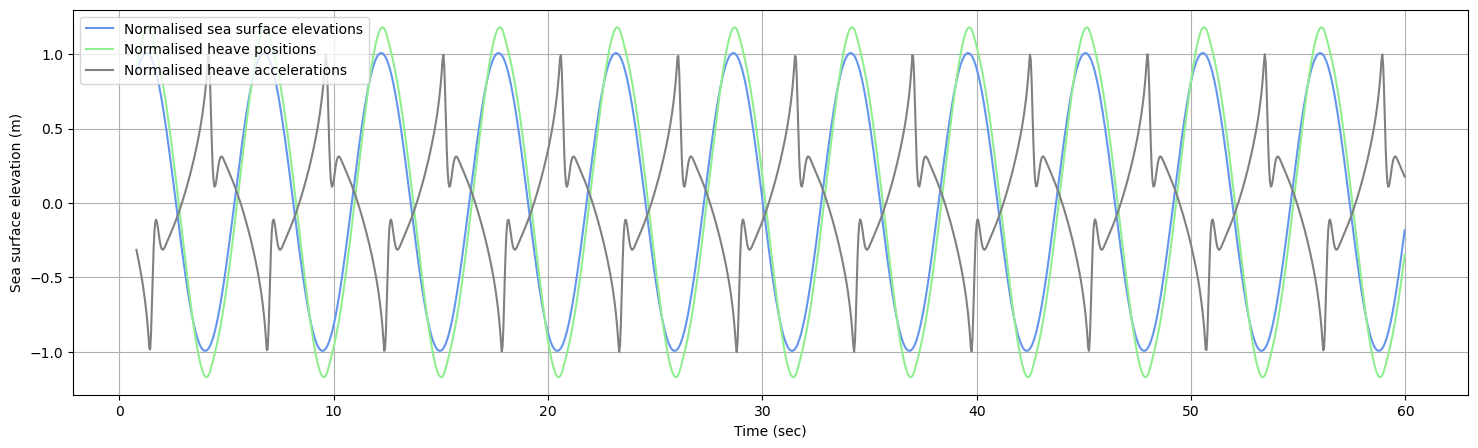

In [9]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(np.arange(0, time_duration, time_step_size/1000)[trim_size:], normalised_elevations, label="Normalised sea surface elevations", color="cornflowerblue")
plt.plot(np.arange(0, time_duration, time_step_size/1000)[trim_size:], normalised_positions, label="Normalised heave positions", color="lightgreen")
plt.plot(np.arange(0, time_duration, time_step_size/1000)[trim_size:], normalised_accelerations, label="Normalised heave accelerations", color="grey")
plt.legend()
plt.grid(True)
plt.xlabel("Time (sec)")
plt.ylabel("Sea surface elevation (m)")

### 2.1 - Estimate frequency

In [10]:
L_1, fhat_1, freq_1, PSD_1, i_max_1 = fast_fourier_transform(elevations)
L_2, fhat_2, freq_2, PSD_2, i_max_2 = fast_fourier_transform([acc.heave for acc in accelerations])

In [11]:
f_max_1 = abs(freq_1[i_max_1])
f_max_2 = abs(freq_2[i_max_2])
print("Peak freq for sea surface elevations = ", f_max_1)
print("Peak freq for ASV_2 = ", f_max_2)

Peak freq for sea surface elevations =  0.18581081081081077
Peak freq for ASV_2 =  0.18581081081081077


In [12]:
sea_surface.py_get_peak_spectral_frequency()

0.18263810872998018

## 3 - Sync motion in a irregular wave
- Same as the previous experiment but using an irregular sea surface.

In [13]:
# Sea surface
count_component_waves = 21
sea_surface = py_Sea_surface(wave_hs, wave_dp, wave_rand_seed, count_component_waves)

In [14]:
# Initialise ASV
asv = py_Asv(asv_spec, sea_surface, position, start_attitude)
# Ensure the ASVs does not surge or sway
asv.py_set_surge_sway_halt(True)

In [15]:
# Simulate
positions, attitudes, accelerations, elevations = simulate(time_duration, sea_surface, asv)

In [16]:
# Trim the results 
trim_size = 20
positions = positions[trim_size:]
attitudes = attitudes[trim_size:]
accelerations = accelerations[trim_size:]
elevations = elevations[trim_size:]

In [17]:
# Normalised results
normalised_elevations = np.array(elevations)
normalised_elevations = [(elevation-normalised_elevations.mean())/normalised_elevations.max() for elevation in normalised_elevations]
normalised_accelerations = np.array([acc.heave for acc in accelerations])
normalised_accelerations = [(acc - normalised_accelerations.mean())/normalised_accelerations.max() for acc in normalised_accelerations]

Text(0, 0.5, 'Sea surface elevation (m)')

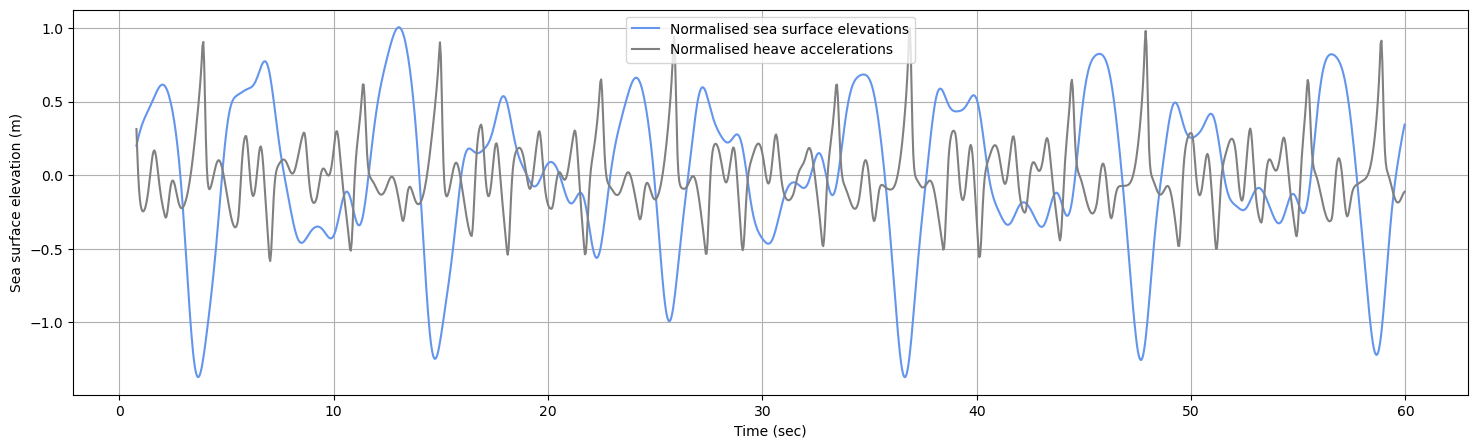

In [18]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(np.arange(0, time_duration, time_step_size/1000)[trim_size:], normalised_elevations, label="Normalised sea surface elevations", color="cornflowerblue")
plt.plot(np.arange(0, time_duration, time_step_size/1000)[trim_size:], normalised_accelerations, label="Normalised heave accelerations", color="grey")
plt.legend()
plt.grid(True)
plt.xlabel("Time (sec)")
plt.ylabel("Sea surface elevation (m)")

### 3.1 - Estimate frequency

In [19]:
L_1, fhat_1, freq_1, PSD_1, i_max_1 = fast_fourier_transform(elevations)
L_2, fhat_2, freq_2, PSD_2, i_max_2 = fast_fourier_transform([acc.heave for acc in accelerations])

In [20]:
f_max_1 = abs(freq_1[i_max_1])
f_max_2 = abs(freq_2[i_max_2])
print("Peak freq for sea surface elevations = ", f_max_1)
print("Peak freq for heave accelerations = ", f_max_2)

Peak freq for sea surface elevations =  0.18581081081081077
Peak freq for heave accelerations =  0.45608108108108103


In [21]:
sea_surface.py_get_peak_spectral_frequency()

0.18263810872998018